# Challenge Sprint 3: Preparação e divisão do dataset

**Objetivo:** preparar e organizar as imagens que serão usadas depois no treinamento de uma CNN: escolher a base, dividir em **Train / Validation / Test**, checar balanceamento, comparar os três conjuntos e definir como as imagens serão padronizadas. *Neste sprint a CNN não é treinada.*

**Fluxo de preparação:**

`Imagem original → Resize / Crop / Padding → Normalização → Imagem padronizada → CNN`

| # | Seção | Requisito do sprint |
|---|---|---|
| 1 | Dataset escolhido | imagens, classes, exemplos |
| 2 | Limpeza | duplicatas (evitar vazamento entre conjuntos) |
| 3 | Divisão dos dados | Train / Validation / Test |
| 4 | Balanceamento das classes | quantidade por classe e desbalanceamento |
| 5 | Medição das imagens | resolução, canais, intervalo dos pixels |
| 6 | Comparação Train × Val × Test | classes, média/desvio, histogramas, canais RGB |
| 7 | Dimensão das imagens | resoluções encontradas |
| 8 | Padronização para a CNN | resize, crop, padding e normalização |
| 9 | Análise final | as 4 perguntas do sprint |

> **Como executar:** *Run All*. Requer `numpy pandas matplotlib pillow scipy scikit-learn kagglehub`. A primeira execução baixa a base (~756 MB) e copia as imagens para `dataset/`; a varredura das imagens leva alguns minutos.

In [1]:
import hashlib, math, os, shutil, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import stats

# ── Configuração do experimento ─────────────────────────────────────────────
SEED = 42                       # reprodutibilidade do split
RATIOS = (0.70, 0.15, 0.15)     # train / val / test
SIZE = 224                      # lado da entrada da CNN
DATASET_DIR = Path("dataset")   # saída: dataset/{train,val,test}/{gato,cao}/
COPY_FILES = True               # False = só calcula, sem copiar as imagens

# ── Estilo dos gráficos (uma cor por entidade em todo o notebook) ───────────
SPLIT_C = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}
SPLIT_N = {"train": "Train", "val": "Validation", "test": "Test"}
SP_C = {"gato": "#e87ba4", "cao": "#4a3aa7"}
SP_N = {"gato": "Gato", "cao": "Cão"}
SPLITS = ("train", "val", "test")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": False, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})


def br(n):        # 5152 -> "5.152"
    return f"{int(round(n)):,}".replace(",", ".")


def pc(x, k=1):   # 0.3234 -> "32,3%"
    return f"{x * 100:.{k}f}%".replace(".", ",")


def num(x, k=2):  # 1.234 -> "1,23"
    return f"{x:.{k}f}".replace(".", ",")


def up(x, k=2):   # arredonda p/ cima: limites superiores nunca ficam otimistas
    return num(math.ceil(x * 10**k) / 10**k, k)


def down(x, k=2): # arredonda p/ baixo: limites inferiores nunca ficam otimistas
    return num(math.floor(x * 10**k) / 10**k, k)

C:\Users\Leona\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Funções de apoio

Rótulos, remoção de duplicatas, split estratificado, padronização (`resize`, `crop`, `padding`) e normalização ficam neste bloco. É o **mesmo código coberto por 22 testes automatizados** (`tests/test_dataprep.py`), escritos antes da implementação (TDD).

In [2]:
"""Funções puras de preparação do dataset (rótulos, split, padronização)."""
import hashlib
from pathlib import Path

import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

SPLITS = ("train", "val", "test")


# ---------- rótulos ----------

def parse_label(filename):
    """'Abyssinian_1.jpg' -> ('gato', 'Abyssinian'); 'beagle_42.jpg' -> ('cao', 'beagle').

    Convenção do Oxford-IIIT Pet: raças de gato começam com maiúscula.
    """
    breed = Path(filename).stem.rsplit("_", 1)[0]
    return ("gato" if breed[0].isupper() else "cao"), breed


# ---------- duplicatas ----------

def file_md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()


def drop_duplicates(paths):
    """Mantém a primeira ocorrência de cada conteúdo idêntico. Retorna (mantidos, removidos)."""
    seen, kept, removed = set(), [], []
    for p in paths:
        digest = file_md5(p)
        if digest in seen:
            removed.append(p)
        else:
            seen.add(digest)
            kept.append(p)
    return kept, removed


# ---------- split estratificado ----------

def assign_splits(strata, ratios=(0.70, 0.15, 0.15), seed=42):
    """Devolve o nome do split ('train'/'val'/'test') de cada item, estratificado por `strata`."""
    if abs(sum(ratios) - 1.0) > 1e-9:
        raise ValueError(f"as razões devem somar 1, recebido {sum(ratios)}")
    train_r, val_r, test_r = ratios
    idx = np.arange(len(strata))
    strata = np.asarray(strata)

    train_idx, rest_idx = train_test_split(
        idx, test_size=val_r + test_r, stratify=strata, random_state=seed
    )
    val_idx, test_idx = train_test_split(
        rest_idx,
        test_size=test_r / (val_r + test_r),
        stratify=strata[rest_idx],
        random_state=seed,
    )

    out = [None] * len(strata)
    for name, members in zip(SPLITS, (train_idx, val_idx, test_idx)):
        for i in members:
            out[i] = name
    return out


# ---------- padronização das imagens ----------

def load_rgb(path):
    """Abre qualquer imagem (JPEG, PNG/GIF disfarçado, L, P, RGBA) como RGB de 3 canais."""
    with Image.open(path) as im:
        return im.convert("RGB")


def resize_center_crop(img, size):
    """Redimensiona o lado menor para `size` (mantém proporção) e recorta o centro size×size."""
    w, h = img.size
    scale = size / min(w, h)
    nw, nh = max(size, round(w * scale)), max(size, round(h * scale))
    img = img.resize((nw, nh), Image.BICUBIC)
    left, top = (nw - size) // 2, (nh - size) // 2
    return img.crop((left, top, left + size, top + size))


def resize_pad(img, size, fill=(0, 0, 0)):
    """Redimensiona o lado maior para `size` (mantém proporção) e completa com `fill` (letterbox)."""
    w, h = img.size
    scale = size / max(w, h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    img = img.resize((nw, nh), Image.BICUBIC)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(img, ((size - nw) // 2, (size - nh) // 2))
    return canvas


def resize_stretch(img, size):
    """Redimensiona direto para size×size, distorcendo a proporção."""
    return img.resize((size, size), Image.BICUBIC)


def aspect_loss(w, h):
    """Fração da área original descartada (crop) ou preenchida com vazio (padding)
    ao levar uma imagem w×h para um quadrado: 1 - lado_menor/lado_maior."""
    return 1 - min(w, h) / max(w, h)


# ---------- normalização ----------

def normalize(arr, mean, std):
    """uint8 HWC [0,255] -> float32 HWC, escalado para [0,1] e padronizado por canal."""
    mean = np.asarray(mean, dtype=np.float32)
    std = np.asarray(std, dtype=np.float32)
    if (std <= 0).any():
        raise ValueError("o desvio-padrão deve ser > 0 em todos os canais")
    x = np.asarray(arr, dtype=np.float32) / 255.0
    return ((x - mean) / std).astype(np.float32)

## 1. Dataset escolhido

Base pública do Kaggle: **`yashdogra/cats-and-dogs`**, com fotos reais de gatos e cães (mesma estrutura de nomes do Oxford-IIIT Pet). Não há pastas por classe: o **rótulo vem do nome do arquivo**, e raças de gato começam com letra maiúscula (`Abyssinian_1.jpg → gato / Abyssinian`; `beagle_42.jpg → cão / beagle`).

**Por que esta base:** tem volume suficiente para dividir em três conjuntos e ainda medir cada um; variedade real de pose, fundo, iluminação e resolução; e um desbalanceamento genuíno gato × cão para discutir (não foi criado artificialmente).

In [3]:
SRC = Path(kagglehub.dataset_download("yashdogra/cats-and-dogs")) / "images"
files = sorted(SRC.glob("*.jpg"))

raw = pd.DataFrame({"file": [p.name for p in files], "path": files})
raw[["species", "breed"]] = [parse_label(n) for n in raw.file]

print(f"Pasta de origem : {SRC}")
print(f"Imagens baixadas: {br(len(raw))}")
print(f"Classes (espécie): {raw.species.nunique()}  ->  {sorted(raw.species.unique())}")
print(f"Raças            : {raw.breed.nunique()}  ({raw[raw.species == 'gato'].breed.nunique()} de gato, "
      f"{raw[raw.species == 'cao'].breed.nunique()} de cão)")
raw[["file", "species", "breed"]].sample(6, random_state=SEED)

Pasta de origem : C:\Users\Leona\.cache\kagglehub\datasets\yashdogra\cats-and-dogs\versions\1\images
Imagens baixadas: 7.390
Classes (espécie): 2  ->  ['cao', 'gato']
Raças            : 37  (12 de gato, 25 de cão)


,file,species,breed
7266,yorkshire_terrier_168.jpg,cao,yorkshire_terrier
3653,keeshond_147.jpg,cao,keeshond
1539,Bombay_42.jpg,gato,Bombay
6071,scottish_terrier_163.jpg,cao,scottish_terrier
4165,Maine_Coon_61.jpg,gato,Maine_Coon
3704,keeshond_193.jpg,cao,keeshond


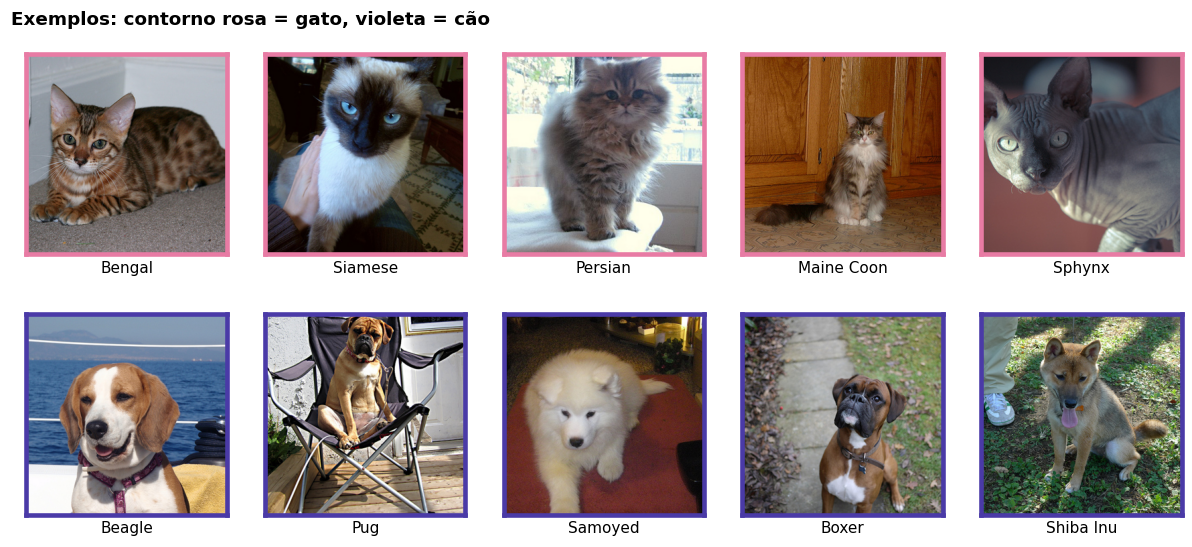

In [4]:
# Exemplos representativos (miniaturas recortadas ao centro só para exibição)
picks = {"gato": ["Bengal", "Siamese", "Persian", "Maine_Coon", "Sphynx"],
         "cao": ["beagle", "pug", "samoyed", "boxer", "shiba_inu"]}
rng = np.random.default_rng(3)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.9))
for r, sp in enumerate(("gato", "cao")):
    for c, breed in enumerate(picks[sp]):
        cand = raw[raw.breed == breed]
        row = cand.iloc[int(rng.integers(len(cand)))]
        ax = axes[r, c]
        ax.imshow(resize_center_crop(load_rgb(row.path), 300))
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(SP_C[sp]); s.set_linewidth(3)
        ax.set_xlabel(breed.replace("_", " ").title(), fontsize=10)
fig.suptitle("Exemplos: contorno rosa = gato, violeta = cão", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); fig.subplots_adjust(top=0.9, hspace=0.3); plt.show()

## 2. Limpeza: duplicatas exatas

Se a mesma foto cair em conjuntos diferentes (por exemplo, Train e Test), a avaliação fica otimista: o modelo "já viu" a imagem. Por isso identifico arquivos **idênticos byte a byte** (hash MD5) e mantenho só um de cada grupo, **antes** de dividir.

In [5]:
with ThreadPoolExecutor() as ex:
    hashes = dict(zip(files, ex.map(file_md5, files)))

by_hash = {}
for p, h in hashes.items():
    by_hash.setdefault(h, []).append(p.name)
dup_groups = [v for v in by_hash.values() if len(v) > 1]
conflicts = [g for g in dup_groups if len({parse_label(n)[1] for n in g}) > 1]

kept, removed = drop_duplicates(files)
print(f"Grupos de arquivos idênticos : {len(dup_groups)}")
print(f"Arquivos removidos           : {len(removed)}")
print(f"Grupos com raças diferentes  : {len(conflicts)}  (rótulos conflitantes)")
print(f"Imagens únicas restantes     : {br(len(kept))}")
print("Exemplo de grupo idêntico    :", dup_groups[0])

Grupos de arquivos idênticos : 29
Arquivos removidos           : 30
Grupos com raças diferentes  : 0  (rótulos conflitantes)
Imagens únicas restantes     : 7.360
Exemplo de grupo idêntico    : ['Bombay_100.jpg', 'Bombay_11.jpg', 'Bombay_192.jpg']


## 3. Divisão dos dados: Train / Validation / Test

**Proporção 70 / 15 / 15**, com split **estratificado por raça** e `seed = 42`.

* **70% treino** (~5 mil imagens): dados suficientes para a CNN aprender pelagem, focinho, orelhas.
* **15% + 15%**: ~1.100 imagens em Validation e em Test dão margem de erro de ≈ ±1,8 p.p. (IC 95%) para uma acurácia de ~90% (±3 p.p. no pior caso, com acurácia de 50%).
* **Estratificar por raça** divide *cada* raça em 70/15/15. Como cada raça pertence a uma só espécie, a proporção **gato/cão e a de raças ficam iguais nos três conjuntos**.
* **Validation** serve para escolher hiperparâmetros e parar o treino; **Test** só é usado uma vez, no final.

In [6]:
df = pd.DataFrame({"file": [p.name for p in kept], "path": kept})
df[["species", "breed"]] = [parse_label(n) for n in df.file]
df["split"] = assign_splits(df.breed.tolist(), ratios=RATIOS, seed=SEED)

tab = pd.crosstab(df.split, df.species).reindex(SPLITS)
tab.insert(0, "imagens", tab.sum(axis=1))
tab.insert(1, "% do total", (tab.imagens / tab.imagens.sum() * 100).round(1))
tab.loc["TOTAL"] = [tab.imagens.sum(), 100.0, tab.gato.sum(), tab.cao.sum()]
tab

species,imagens,% do total,cao,gato
split,,,,
train,5152.0,70.0,3486.0,1666.0
val,1104.0,15.0,746.0,358.0
test,1104.0,15.0,748.0,356.0
TOTAL,7360.0,100.0,2380.0,4980.0


In [7]:
# Cópia física das imagens para dataset/<split>/<espécie>/  (pronto para ImageFolder / image_dataset_from_directory)
if COPY_FILES:
    for row in df.itertuples():
        dest = DATASET_DIR / row.split / row.species
        dest.mkdir(parents=True, exist_ok=True)
        if not (dest / row.file).exists():
            shutil.copy2(row.path, dest / row.file)
    for s in SPLITS:
        for sp in ("gato", "cao"):
            print(f"dataset/{s}/{sp:<5}: {br(len(list((DATASET_DIR / s / sp).glob('*.jpg'))))} imagens")
df[["file", "species", "breed", "split"]].to_csv("splits.csv", index=False)

dataset/train/gato : 1.666 imagens
dataset/train/cao  : 3.486 imagens
dataset/val/gato : 358 imagens
dataset/val/cao  : 746 imagens
dataset/test/gato : 356 imagens
dataset/test/cao  : 748 imagens


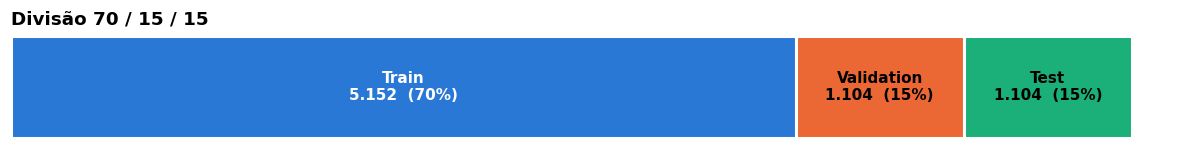

In [8]:
# Visualização da divisão
sizes = df.split.value_counts().reindex(SPLITS)
fig, ax = plt.subplots(figsize=(11, 1.5))
left = 0
for s in SPLITS:
    ax.barh(0, sizes[s], left=left, color=SPLIT_C[s], edgecolor="white", linewidth=2, height=0.7)
    ax.text(left + sizes[s] / 2, 0, f"{SPLIT_N[s]}\n{br(sizes[s])}  ({pc(sizes[s] / len(df), 0)})",
            ha="center", va="center", fontweight="bold", color="white" if s == "train" else "black")
    left += sizes[s]
ax.axis("off"); ax.set_title("Divisão 70 / 15 / 15", pad=4)
plt.tight_layout(); plt.show()

## 4. Balanceamento das classes

Há **dois níveis de rótulo** neste dataset, e a resposta é diferente em cada um:

* **Espécie** (gato × cão): o problema binário natural da base.
* **Raça** (37 classes): uma tarefa mais difícil, que pode ser explorada depois.

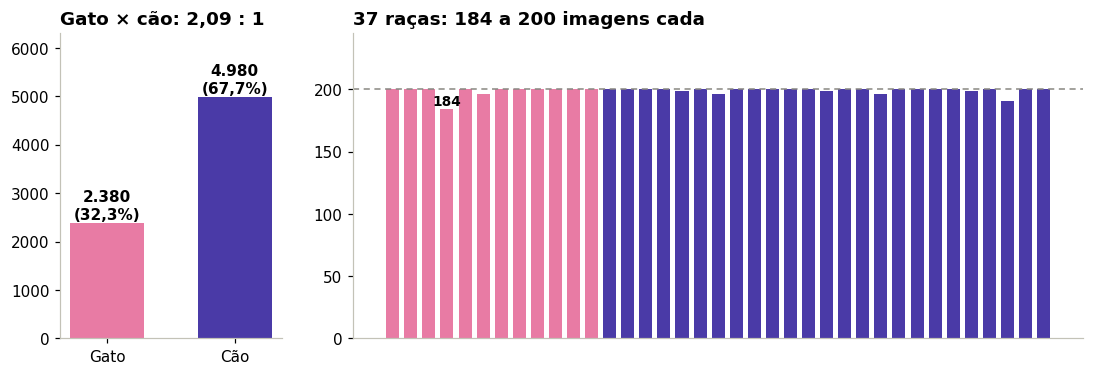

Por espécie: gato = 2.380 (32,3%) | cão = 4.980 (67,7%) | razão = 2,09 : 1
Por raça   : mín = 184 (Bombay) | máx = 200 | razão = 1,09 : 1
Baseline ingênuo (sempre responder 'cão'): acurácia = 67,7%


In [9]:
sp_counts = df.species.value_counts()
br_counts = df.breed.value_counts()
ratio = sp_counts.max() / sp_counts.min()

fig = plt.figure(figsize=(12, 3.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 3.3], wspace=0.15)

ax = fig.add_subplot(gs[0])
for i, sp in enumerate(("gato", "cao")):
    ax.bar(i, sp_counts[sp], width=0.58, color=SP_C[sp])
    ax.text(i, sp_counts[sp] + 90, f"{br(sp_counts[sp])}\n({pc(sp_counts[sp] / len(df))})",
            ha="center", fontweight="bold")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Gato", "Cão"]); ax.set_ylim(0, 6300)
ax.set_title(f"Gato × cão: {num(ratio)} : 1")

ax = fig.add_subplot(gs[1])
order = sorted(br_counts.index, key=lambda b: (parse_label(b + "_1.jpg")[0] != "gato", b.lower()))
ax.bar(range(len(order)), [br_counts[b] for b in order], width=0.72,
       color=[SP_C[parse_label(b + "_1.jpg")[0]] for b in order])
ax.axhline(200, color="#898781", lw=1, ls=(0, (4, 3)))
for b in (br_counts.idxmin(),):
    ax.text(order.index(b), br_counts[b] + 3, str(br_counts[b]), ha="center", fontweight="bold", fontsize=9)
ax.set_xticks([]); ax.set_ylim(0, 245)
ax.set_title(f"{len(order)} raças: {br_counts.min()} a {br_counts.max()} imagens cada")
plt.show()

print(f"Por espécie: gato = {br(sp_counts['gato'])} ({pc(sp_counts['gato'] / len(df))}) | "
      f"cão = {br(sp_counts['cao'])} ({pc(sp_counts['cao'] / len(df))}) | razão = {num(ratio)} : 1")
print(f"Por raça   : mín = {br_counts.min()} ({br_counts.idxmin()}) | máx = {br_counts.max()} | "
      f"razão = {num(br_counts.max() / br_counts.min())} : 1")
print(f"Baseline ingênuo (sempre responder 'cão'): acurácia = {pc(sp_counts['cao'] / len(df))}")

**Resposta:** por **raça** o dataset está **balanceado**. Por **espécie** (gato × cão) **não está**: há mais que o dobro de cães. Um modelo que responda sempre "cão" já acertaria ~68% sem aprender nada, então a acurácia sozinha engana.

**Como tratar** (sem alterar Validation/Test, que devem refletir o mundo real):

1. **Pesos de classe na loss**, `n_total / (n_classes · n_classe)` calculado só no Train (valores logo abaixo).
2. **Métricas que enxergam a minoria:** F1 e recall por classe e matriz de confusão, não só acurácia.
3. **Sem undersampling**: descartaria ~2.600 fotos de cães. *Data augmentation* só no Train.

In [10]:
tr = df[df.split == "train"].species.value_counts()
class_weight = {sp: float(len(df[df.split == "train"]) / (2 * tr[sp])) for sp in ("gato", "cao")}
print("class_weight (calculado no Train):", {k: round(v, 3) for k, v in class_weight.items()})

class_weight (calculado no Train): {'gato': 1.546, 'cao': 0.739}


## 5. Medição das imagens

Uma única passada lê cada imagem e registra: **formato, modo (canais), largura, altura**, o **histograma de 256 níveis por canal RGB** (resolução original) e o histograma da versão já padronizada (resize + center crop 224). Com os histogramas obtenho média, desvio-padrão e intervalo dos pixels **exatos** de cada conjunto, sem guardar as imagens na memória.

In [11]:
BINS = np.arange(256)


def hist_rgb(arr):
    return np.stack([np.bincount(arr[..., c].ravel(), minlength=256) for c in range(3)])


def moments(h):
    # média e desvio-padrão por canal (escala 0-255) a partir de histogramas (3, 256)
    n = h.sum(axis=1)
    mean = (h * BINS).sum(axis=1) / n
    var = (h * BINS**2).sum(axis=1) / n - mean**2
    return mean, np.sqrt(var)


def analyse(path):
    with Image.open(path) as im:
        fmt, mode = im.format, im.mode
    img = load_rgb(path)                       # sempre 3 canais
    h_nat = hist_rgb(np.asarray(img))          # pixels na resolução original
    h_pre = hist_rgb(np.asarray(resize_center_crop(img, SIZE)))  # pixels já padronizados
    mean, _ = moments(h_nat)
    all_mean = mean.mean()
    all_var = (h_nat.sum(axis=0) * BINS**2).sum() / h_nat.sum() - all_mean**2
    return {"format": fmt, "mode": mode, "width": img.width, "height": img.height,
            "brightness": 0.299 * mean[0] + 0.587 * mean[1] + 0.114 * mean[2],
            "contrast": float(np.sqrt(all_var)), "h_nat": h_nat, "h_pre": h_pre}


t0 = time.time()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    rows = list(ex.map(analyse, df.path))
print(f"{br(len(rows))} imagens analisadas em {time.time() - t0:.0f}s")

hn = np.stack([r.pop("h_nat") for r in rows])
hp = np.stack([r.pop("h_pre") for r in rows])
df = pd.concat([df, pd.DataFrame(rows)], axis=1)
df["aspect"] = df.width / df.height
df["min_side"] = df[["width", "height"]].min(axis=1)
df["aspect_loss"] = [aspect_loss(w, h) for w, h in zip(df.width, df.height)]

mask = {s: (df.split == s).to_numpy() for s in SPLITS}
H_nat = {s: hn[m].sum(axis=0) for s, m in mask.items()}   # histogramas por split (resolução original)
H_pre = {s: hp[m].sum(axis=0) for s, m in mask.items()}   # histogramas por split (já padronizadas)
df[["file", "species", "breed", "split", "format", "mode", "width", "height", "brightness", "contrast"]].head()

7.360 imagens analisadas em 23s


,file,species,breed,split,format,mode,width,height,brightness,contrast
0,Abyssinian_1.jpg,gato,Abyssinian,train,JPEG,RGB,600,400,73.483705,38.814772
1,Abyssinian_10.jpg,gato,Abyssinian,val,JPEG,RGB,375,500,69.914281,53.705579
2,Abyssinian_100.jpg,gato,Abyssinian,train,JPEG,RGB,394,500,142.077698,84.178055
3,Abyssinian_101.jpg,gato,Abyssinian,train,JPEG,RGB,450,313,138.724565,81.089826
4,Abyssinian_102.jpg,gato,Abyssinian,train,JPEG,RGB,500,465,135.826467,67.131609


## 6. Comparação entre Train, Validation e Test

> O objetivo **não** é deixar os três conjuntos artificialmente idênticos, e sim verificar se **não há diferenças visuais grandes** que atrapalhem o treino e a avaliação.

### 6.1 Distribuição das classes

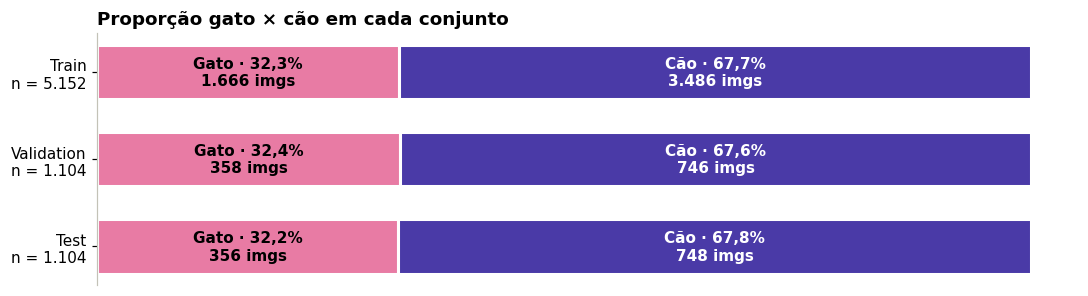

χ² espécie × conjunto: χ² = 0.008, p = 0.996
χ² raça    × conjunto: χ² = 0.126, p = 1.000
p alto = não há evidência de que a composição de classes difira entre os conjuntos.


In [12]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for y, s in enumerate(SPLITS):
    d = df[df.split == s]
    c = d.species.value_counts()
    left = 0
    for sp in ("gato", "cao"):
        p = c[sp] / len(d) * 100
        ax.barh(y, p, left=left, height=0.62, color=SP_C[sp], edgecolor="white", linewidth=2)
        ax.text(left + p / 2, y, f"{SP_N[sp]} · {num(p, 1)}%\n{br(c[sp])} imgs", ha="center", va="center",
                fontweight="bold", color="white" if sp == "cao" else "black")
        left += p
ax.set_yticks(range(3)); ax.set_yticklabels([f"{SPLIT_N[s]}\nn = {br(mask[s].sum())}" for s in SPLITS])
ax.invert_yaxis(); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
ax.set_title("Proporção gato × cão em cada conjunto"); plt.tight_layout(); plt.show()

chi_sp = stats.chi2_contingency(pd.crosstab(df.split, df.species))
chi_br = stats.chi2_contingency(pd.crosstab(df.split, df.breed))
print(f"χ² espécie × conjunto: χ² = {chi_sp[0]:.3f}, p = {chi_sp[1]:.3f}")
print(f"χ² raça    × conjunto: χ² = {chi_br[0]:.3f}, p = {chi_br[1]:.3f}")
print("p alto = não há evidência de que a composição de classes difira entre os conjuntos.")

### 6.2 Média, desvio-padrão e intervalo dos pixels

R      G      B  min  max
Train      média   122.9  114.8  101.0    0  255
           desvio   68.9   67.7   69.7    0  255
Validation média   123.0  113.3  100.8    0  255
           desvio   67.3   66.3   68.9    0  255
Test       média   122.0  113.8   99.4    0  255
           desvio   68.9   67.8   69.9    0  255

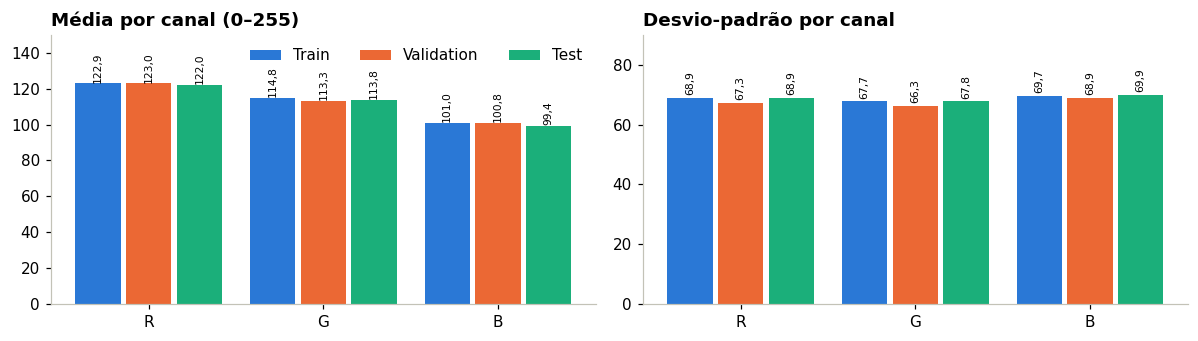

In [13]:
px = {}
for s in SPLITS:
    mean, std = moments(H_nat[s])
    present = np.nonzero(H_nat[s].sum(axis=0))[0]
    px[s] = {"mean": mean, "std": std, "min": present.min(), "max": present.max()}

tbl = pd.DataFrame({
    (SPLIT_N[s], m): [px[s][k][c] for c in range(3)] for s in SPLITS for m, k in (("média", "mean"), ("desvio", "std"))
}, index=["R", "G", "B"]).round(1).T
tbl["min"] = [px[s]["min"] for s in SPLITS for _ in range(2)]
tbl["max"] = [px[s]["max"] for s in SPLITS for _ in range(2)]
display(tbl)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, key, title in ((axes[0], "mean", "Média por canal (0–255)"), (axes[1], "std", "Desvio-padrão por canal")):
    w = 0.26
    for j, s in enumerate(SPLITS):
        xs = np.arange(3) + (j - 1) * (w + 0.03)
        ax.bar(xs, px[s][key], width=w, color=SPLIT_C[s], label=SPLIT_N[s])
        for x, v in zip(xs, px[s][key]):
            ax.text(x, v + 1.5, num(v, 1), ha="center", fontsize=7, rotation=90)
    ax.set_xticks(range(3)); ax.set_xticklabels(["R", "G", "B"]); ax.set_title(title)
    ax.set_ylim(0, 150 if key == "mean" else 90)
axes[0].legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout(); plt.show()

### 6.3 Histogramas de intensidade por canal RGB

Em cima, o histograma de cada conjunto (faixas de 4 níveis, em % dos pixels). Embaixo, a **diferença** de Validation e Test em relação ao Train, em pontos percentuais.

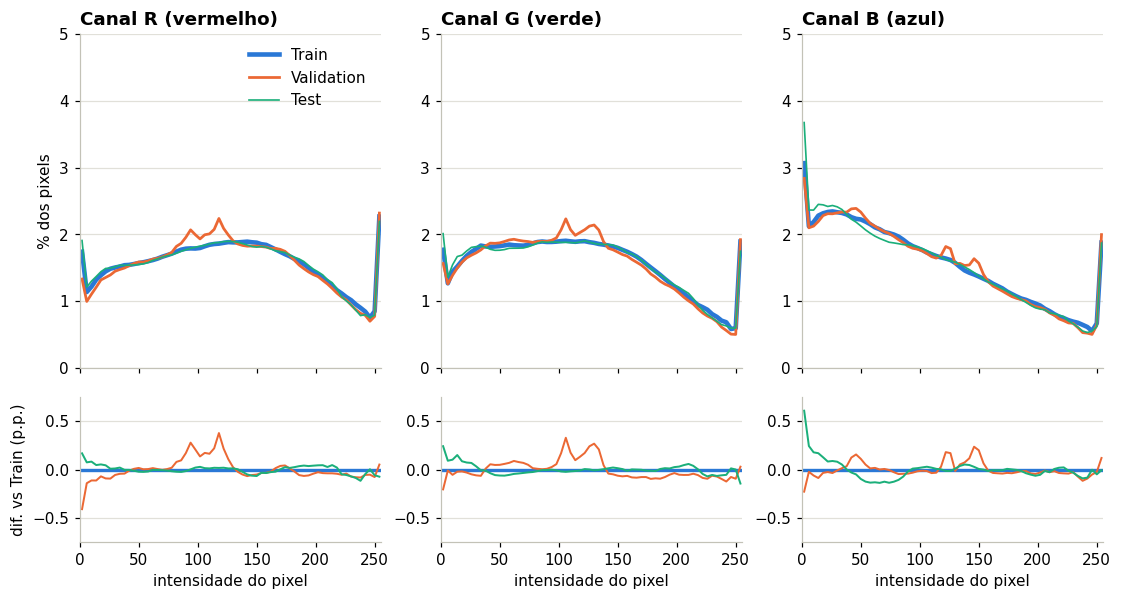

In [14]:
x = np.arange(64) * 4 + 2
def norm_hist(s, c):
    h = H_nat[s][c].astype(float)
    return h.reshape(64, 4).sum(axis=1) / h.sum() * 100

fig, axes = plt.subplots(2, 3, figsize=(12, 6), gridspec_kw={"height_ratios": [2.3, 1], "hspace": 0.12})
for c, name in enumerate(["Canal R (vermelho)", "Canal G (verde)", "Canal B (azul)"]):
    top, bot = axes[0, c], axes[1, c]
    for s, lw in (("train", 3.0), ("val", 1.8), ("test", 1.1)):
        top.plot(x, norm_hist(s, c), color=SPLIT_C[s], lw=lw, label=SPLIT_N[s])
    top.set_title(name); top.set_xlim(0, 255); top.set_ylim(0, 5); top.tick_params(labelbottom=False)
    top.yaxis.grid(True, color="#e1e0d9"); top.set_axisbelow(True)
    bot.axhline(0, color=SPLIT_C["train"], lw=2.2)
    for s in ("val", "test"):
        bot.plot(x, norm_hist(s, c) - norm_hist("train", c), color=SPLIT_C[s], lw=1.3)
    bot.set_xlim(0, 255); bot.set_ylim(-0.75, 0.75); bot.set_xlabel("intensidade do pixel")
    bot.yaxis.grid(True, color="#e1e0d9"); bot.set_axisbelow(True)
    if c == 0:
        top.set_ylabel("% dos pixels"); bot.set_ylabel("dif. vs Train (p.p.)")
axes[0, 0].legend(frameon=False)
plt.show()

### 6.4 Testes de semelhança

* **KS de duas amostras** no *brilho médio* e no *contraste* (desvio-padrão) de cada imagem. **D** é a distância máxima entre as curvas acumuladas (0 = idênticas); com milhares de imagens o p-valor é muito sensível, então D é a medida de tamanho do efeito.
* **Distância de Wasserstein** entre os histogramas RGB, em **níveis de intensidade** (de 0 a 255).

In [15]:
pairs = [("train", "val"), ("train", "test"), ("val", "test")]
rows_ = []
for a, b in pairs:
    da, db = df[df.split == a], df[df.split == b]
    ks_b = stats.ks_2samp(da.brightness, db.brightness)
    ks_c = stats.ks_2samp(da.contrast, db.contrast)
    w1 = [stats.wasserstein_distance(BINS, BINS, H_nat[a][c], H_nat[b][c]) for c in range(3)]
    rows_.append({"par": f"{SPLIT_N[a]} × {SPLIT_N[b]}",
                  "KS brilho D": ks_b.statistic, "p (brilho)": ks_b.pvalue,
                  "KS contraste D": ks_c.statistic, "p (contraste)": ks_c.pvalue,
                  "Wasserstein R": w1[0], "G": w1[1], "B": w1[2],
                  "Δ média RGB máx (de 255)": np.abs(px[a]["mean"] - px[b]["mean"]).max()})
cmp_tbl = pd.DataFrame(rows_).set_index("par").round(3)
display(cmp_tbl)

,KS brilho D,p (brilho),KS contraste D,p (contraste),Wasserstein R,G,B,Δ média RGB máx (de 255)
par,,,,,,,,
Train × Validation,0.018,0.933,0.026,0.574,1.896,1.864,0.797,1.420
Train × Test,0.028,0.471,0.028,0.465,0.907,0.987,1.656,1.653
Validation × Test,0.030,0.708,0.027,0.810,1.924,1.937,1.567,1.415


**Leitura:** as curvas dos três conjuntos praticamente se sobrepõem nos 3 canais. As diferenças do gráfico inferior ficam abaixo de ~0,6 p.p. por faixa, concentradas nas pontas (pixels pretos/saturados) e num leve pico de Validation perto de 128, compatível com ruído de amostragem de ~1.100 imagens. O KS dá D pequeno e a maior diferença entre médias RGB é de cerca de 1–2 níveis em 255. **Não há sinal de que Validation ou Test sejam visualmente diferentes do Train.**

## 7. Dimensão das imagens: resolução, canais e intervalo dos pixels

In [16]:
print("Formato real dos arquivos :", dict(Counter(df.format)))
print("Modo (canais) na origem   :", dict(Counter(df["mode"])), " -> convertidos para RGB (3 canais)")
print("Canais após load_rgb      : 3 em", br(len(df)), "imagens")
print("Intervalo dos pixels      : 0 a 255 (uint8) nos 3 conjuntos:",
      {SPLIT_N[s]: (int(px[s]["min"]), int(px[s]["max"])) for s in SPLITS})
print(f"Resoluções distintas      : {br(df.groupby(['width', 'height']).ngroups)}")
top5 = Counter(zip(df.width, df.height)).most_common(5)
print("Mais comuns               :", ", ".join(f"{w}×{h} ({pc(n / len(df))})" for (w, h), n in top5))
display(df[["width", "height", "min_side", "aspect"]].describe(percentiles=[.05, .5, .95]).round(2).T)

Formato real dos arquivos : {'JPEG': 7350, 'GIF': 6, 'PNG': 4}
Modo (canais) na origem   : {'RGB': 7348, 'P': 6, 'RGBA': 3, 'L': 3}  -> convertidos para RGB (3 canais)
Canais após load_rgb      : 3 em 7.360 imagens
Intervalo dos pixels      : 0 a 255 (uint8) nos 3 conjuntos: {'Train': (0, 255), 'Validation': (0, 255), 'Test': (0, 255)}
Resoluções distintas      : 1.022
Mais comuns               : 500×375 (19,3%), 500×333 (14,5%), 375×500 (6,9%), 333×500 (6,9%), 300×225 (3,5%)


,count,mean,std,min,5%,50%,95%,max
width,7360.0,437.06,115.84,114.00,281.00,500.00,500.00,3264.00
height,7360.0,391.24,109.45,103.00,225.00,375.00,500.00,2606.00
min_side,7360.0,349.45,83.73,103.00,225.00,335.00,456.00,2448.00
aspect,7360.0,1.17,0.33,0.42,0.67,1.33,1.51,2.56


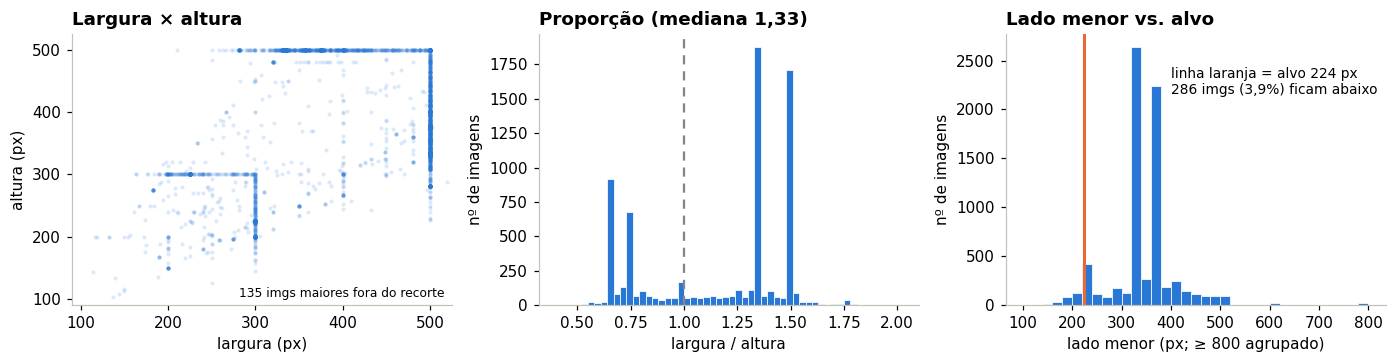

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
blue = SPLIT_C["train"]
ax = axes[0]
inside = (df.width <= 520) & (df.height <= 520)
ax.scatter(df.width[inside], df.height[inside], s=7, color=blue, alpha=0.16, linewidths=0)
ax.set_xlim(90, 525); ax.set_ylim(90, 525); ax.set_xlabel("largura (px)"); ax.set_ylabel("altura (px)")
ax.set_title("Largura × altura"); ax.text(0.98, 0.03, f"{(~inside).sum()} imgs maiores fora do recorte",
                                          transform=ax.transAxes, ha="right", fontsize=8)
ax = axes[1]
ax.hist(df.aspect, bins=np.arange(0.4, 2.02, 0.03), color=blue, edgecolor="white", lw=0.5)
ax.axvline(1.0, color="#898781", ls=(0, (4, 3))); ax.set_xlabel("largura / altura"); ax.set_ylabel("nº de imagens")
ax.set_title(f"Proporção (mediana {num(df.aspect.median())})")
ax = axes[2]
ax.hist(df.min_side.clip(upper=800), bins=np.arange(100, 820, 20), color=blue, edgecolor="white", lw=0.5)
small = int((df.min_side < SIZE).sum())
ax.axvline(SIZE, color=SPLIT_C["val"], lw=2)
ax.text(400, ax.get_ylim()[1] * 0.78, f"linha laranja = alvo {SIZE} px\n{small} imgs ({pc(small / len(df))}) ficam abaixo", fontsize=9)
ax.set_xlabel("lado menor (px; ≥ 800 agrupado)"); ax.set_ylabel("nº de imagens"); ax.set_title("Lado menor vs. alvo")
plt.tight_layout(); plt.show()

**Leitura:** as imagens são muito heterogêneas: centenas de resoluções, de ~100 px a mais de 3 mil px de lado. A grande maioria é **4:3 (paisagem) ou 3:4 (retrato)** e quase nenhuma é quadrada. Todas viram **RGB de 3 canais** (havia GIF, PNG, tons de cinza e RGBA disfarçados de `.jpg`). Para formar batches e alimentar as camadas densas finais, a CNN precisa de **entrada de tamanho fixo**, então é necessário padronizar.

## 8. Padronização para a CNN

**Entrada escolhida: `224 × 224 × 3`**, tamanho padrão de backbones pré-treinados e um bom equilíbrio entre detalhe e custo. Só uma pequena fração das imagens tem lado menor abaixo de 224 (e será ampliada).

Há três formas de levar uma imagem retangular a um quadrado:

| Estratégia | O que faz | Custo |
|---|---|---|
| **Resize direto** | estica para 224×224 | distorce a proporção (focinho/orelhas deformados) |
| **Resize + center crop** | lado menor → 224 e recorta o centro | descarta parte das bordas |
| **Resize + padding** | lado maior → 224 e completa com preto | a mesma fração da entrada vira pixels sem informação |

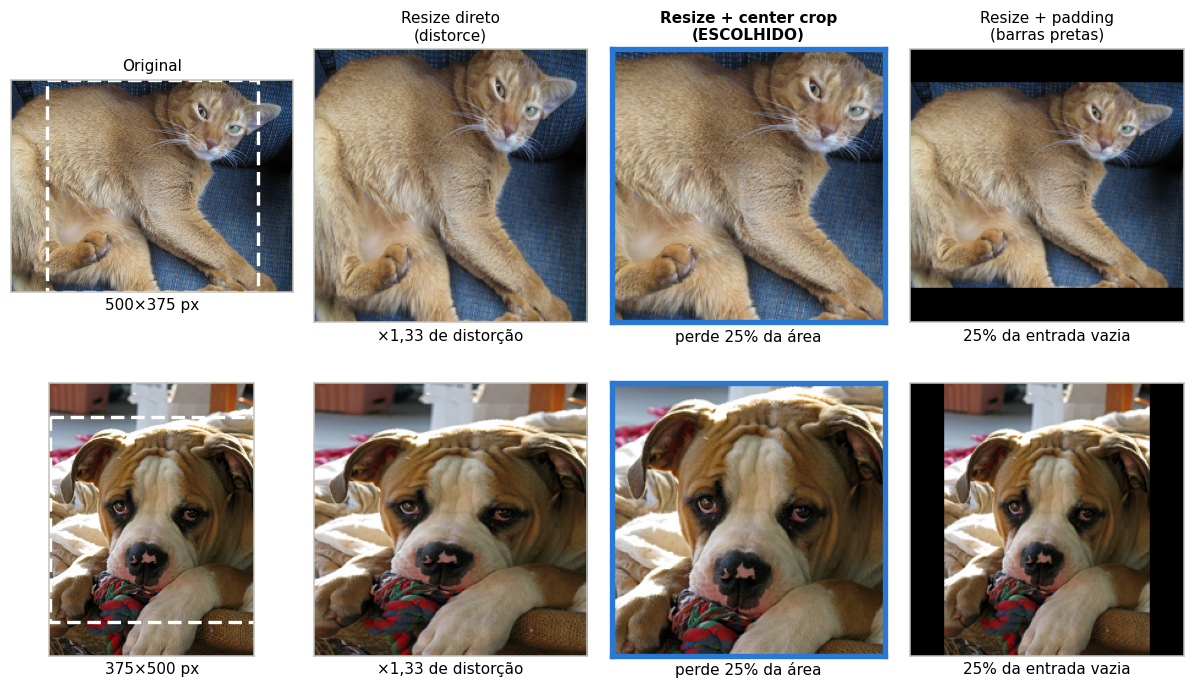

Fração descartada pelo crop (= fração vazia no padding): média 26,7% | mediana 25,0% | p90 33,4% | máx 61,0%
Distorção do resize direto (mediana): ×1,33
Imagens quase quadradas (perda < 5%): 4,3%


In [18]:
tr_ = df[df.split == "train"].sort_values("file")
a = tr_[(tr_.species == "gato") & (tr_.width == 500) & (tr_.height == 375)].iloc[7]
b = tr_[(tr_.species == "cao") & (tr_.width == 375) & (tr_.height == 500)].iloc[5]
cols = ["Original", "Resize direto\n(distorce)", "Resize + center crop\n(ESCOLHIDO)", "Resize + padding\n(barras pretas)"]

fig, axes = plt.subplots(2, 4, figsize=(11, 6.2))
for r, row in enumerate((a, b)):
    img = load_rgb(row.path); w, h = img.size
    outs = [img, resize_stretch(img, SIZE), resize_center_crop(img, SIZE), resize_pad(img, SIZE)]
    for c, o in enumerate(outs):
        ax = axes[r, c]; ax.imshow(o); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor(SPLIT_C["train"] if c == 2 else "#c3c2b7"); s.set_linewidth(3.5 if c == 2 else 1)
        if r == 0:
            ax.set_title(cols[c], fontsize=10, fontweight="bold" if c == 2 else "normal", loc="center")
    m = min(w, h)
    axes[r, 0].add_patch(Rectangle(((w - m) / 2, (h - m) / 2), m, m, fill=False, edgecolor="white", lw=2.2, ls=(0, (4, 2))))
    axes[r, 0].set_xlabel(f"{w}×{h} px")
    axes[r, 1].set_xlabel(f"×{num(max(w / h, h / w))} de distorção")
    axes[r, 2].set_xlabel(f"perde {pc(aspect_loss(w, h), 0)} da área")
    axes[r, 3].set_xlabel(f"{pc(aspect_loss(w, h), 0)} da entrada vazia")
plt.tight_layout(); fig.subplots_adjust(hspace=0.22); plt.show()

al = df.aspect_loss
print(f"Fração descartada pelo crop (= fração vazia no padding): média {pc(al.mean())} | mediana {pc(al.median())} | "
      f"p90 {pc(al.quantile(.9))} | máx {pc(al.max())}")
print(f"Distorção do resize direto (mediana): ×{num(np.maximum(df.aspect, 1 / df.aspect).median())}")
print(f"Imagens quase quadradas (perda < 5%): {pc((al < .05).mean())}")

**Decisão: `resize (lado menor → 224, bicúbico) + center crop 224×224`.**

* **Resize mantendo a proporção**, porque esticar distorce a forma do animal, justamente o que a CNN precisa reconhecer.
* **Crop em vez de padding**: o custo em área é o mesmo, mas o crop descarta só as bordas, enquanto o padding preenche uma faixa larga com pixels pretos que não carregam informação e gastam capacidade da rede. *Premissa:* o animal está perto do centro (vale nos exemplos acima; não foi medido em todas as imagens).
* **Validation e Test** usam sempre esse mesmo pipeline **determinístico**. *Data augmentation* (flip horizontal, `RandomResizedCrop`) fica só no Train.

### Normalização

`x / 255` leva os pixels a `[0, 1]`; depois `(x − μ) / σ` por canal centraliza e escala os dados, o que estabiliza e acelera o treino. **μ e σ são calculados só no Train**: usar Validation/Test aqui vazaria informação. As estatísticas são medidas nas imagens **já recortadas** (a entrada real da CNN).

In [19]:
tr_mean, tr_std = moments(H_pre["train"])
MEAN, STD = tr_mean / 255, tr_std / 255
IMAGENET_MEAN, IMAGENET_STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

print("Constantes de normalização (só do Train, imagens 224×224)")
print("  MEAN =", np.round(MEAN, 4), "   ImageNet:", IMAGENET_MEAN)
print("  STD  =", np.round(STD, 4), "   ImageNet:", IMAGENET_STD)
print("  (com backbone pré-treinado, usar as constantes do ImageNet)\n")

chk = []
for s in SPLITS:
    m, sd = moments(H_pre[s])
    chk.append({"conjunto": SPLIT_N[s],
                **{f"μ {ch}": v for ch, v in zip("RGB", (m / 255 - MEAN) / STD)},
                **{f"σ {ch}": v for ch, v in zip("RGB", (sd / 255) / STD)}})
print("Após normalizar com as constantes do Train (esperado: μ ≈ 0 e σ ≈ 1):")
display(pd.DataFrame(chk).set_index("conjunto").round(3))

Constantes de normalização (só do Train, imagens 224×224)
  MEAN = [0.4865 0.4519 0.3993]    ImageNet: [0.485 0.456 0.406]
  STD  = [0.2648 0.2596 0.267 ]    ImageNet: [0.229 0.224 0.225]
  (com backbone pré-treinado, usar as constantes do ImageNet)

Após normalizar com as constantes do Train (esperado: μ ≈ 0 e σ ≈ 1):


,μ R,μ G,μ B,σ R,σ G,σ B
conjunto,,,,,,
Train,0.000,0.000,0.000,1.000,1.000,1.000
Validation,-0.000,-0.013,-0.009,0.994,0.996,1.006
Test,-0.003,-0.008,-0.019,0.999,1.000,0.999


In [20]:
# Pipeline completo, de ponta a ponta: imagem original -> resize -> crop -> normalização -> tensor para a CNN
def preprocess(path, mean=MEAN, std=STD, size=SIZE):
    img = load_rgb(path)                       # 3 canais garantidos
    img = resize_center_crop(img, size)        # 224 × 224
    return normalize(np.asarray(img), mean, std)   # float32, (x/255 - μ)/σ


batch = np.stack([preprocess(p) for p in df[df.split == "val"].path.head(8)])
print("batch (N, H, W, C):", batch.shape, "| dtype:", batch.dtype)
print("μ por canal:", np.round(batch.reshape(-1, 3).mean(0), 3), "| σ por canal:", np.round(batch.reshape(-1, 3).std(0), 3))
print("valores: min", batch.min().round(2), "| max", batch.max().round(2), "(já não estão em [0,1]: são desvios em relação à média do Train)")
print("Obs.: com só 8 imagens, μ e σ do lote não são exatamente 0 e 1; isso só vale para o conjunto inteiro (tabela acima).")
print("Para PyTorch (N, C, H, W):", np.transpose(batch, (0, 3, 1, 2)).shape)

batch (N, H, W, C): (8, 224, 224, 3) | dtype: float32
μ por canal: [ 0.088 -0.253 -0.192] | σ por canal: [0.924 0.804 0.833]
valores: min -1.84 | max 2.25 (já não estão em [0,1]: são desvios em relação à média do Train)
Obs.: com só 8 imagens, μ e σ do lote não são exatamente 0 e 1; isso só vale para o conjunto inteiro (tabela acima).
Para PyTorch (N, C, H, W): (8, 3, 224, 224)


## 9. Análise final

As quatro perguntas do sprint, respondidas com os números calculados acima.

In [21]:
mean_diff = cmp_tbl["Δ média RGB máx (de 255)"].max()
ks_D = cmp_tbl[["KS brilho D", "KS contraste D"]].to_numpy().max()
ks_p_min = cmp_tbl[["p (brilho)", "p (contraste)"]].to_numpy().min()
post = pd.DataFrame(chk).set_index("conjunto").loc[["Validation", "Test"]]
post_mu = post[[c for c in post.columns if c.startswith("μ")]].abs().to_numpy().max()
post_sd = post[[c for c in post.columns if c.startswith("σ")]].to_numpy()

display(Markdown(f"""
### 1. O dataset está balanceado?
**Parcialmente.** Por **raça**, sim: {br_counts.min()} a {br_counts.max()} imagens por raça (razão {num(br_counts.max() / br_counts.min())} : 1).
Por **espécie**, não: {br(sp_counts['gato'])} gatos ({pc(sp_counts['gato'] / len(df))}) contra {br(sp_counts['cao'])} cães ({pc(sp_counts['cao'] / len(df))}), razão **{num(ratio)} : 1**.
**Tratamento:** pesos de classe (gato ≈ {num(class_weight['gato'])}, cão ≈ {num(class_weight['cao'])}), F1/recall por classe e matriz de confusão, sem undersampling.

### 2. Train, Validation e Test têm características semelhantes?
**Sim.** Proporção de classes praticamente idêntica (χ² p = {num(chi_sp[1], 3)}); médias RGB a no máximo {up(mean_diff, 2)} níveis de 255;
KS com D ≤ {up(ks_D, 3)} (p ≥ {down(ks_p_min, 2)}); histogramas RGB quase sobrepostos e intervalo de pixels idêntico (0–255).
As pequenas diferenças são ruído de amostragem, não viés de seleção.

### 3. As imagens estão adequadamente padronizadas?
**Sim.** Todas passam por `resize (proporção fixa) → center crop → normalização` e saem como **{SIZE}×{SIZE}×3 (float32)**.
Com μ e σ calculados só no Train, Validation e Test ficam com |μ| ≤ {up(post_mu, 3)} e σ entre {down(post_sd.min(), 3)} e {up(post_sd.max(), 3)}.

### 4. O dataset está pronto para o treinamento de uma CNN?
**Sim, com 3 cuidados:**
1. Aplicar **pesos de classe** e acompanhar **F1/recall**, não só acurácia.
2. Usar o **Test uma única vez**, no final.
3. Foram removidas só duplicatas **exatas**; *quase*-duplicatas podem existir. Além disso, {small} imagens ({pc(small / len(df))}) têm lado menor < {SIZE} e serão ampliadas, e o center crop supõe o animal próximo do centro.
"""))


### 1. O dataset está balanceado?
**Parcialmente.** Por **raça**, sim: 184 a 200 imagens por raça (razão 1,09 : 1).
Por **espécie**, não: 2.380 gatos (32,3%) contra 4.980 cães (67,7%), razão **2,09 : 1**.
**Tratamento:** pesos de classe (gato ≈ 1,55, cão ≈ 0,74), F1/recall por classe e matriz de confusão, sem undersampling.

### 2. Train, Validation e Test têm características semelhantes?
**Sim.** Proporção de classes praticamente idêntica (χ² p = 0,996); médias RGB a no máximo 1,66 níveis de 255;
KS com D ≤ 0,030 (p ≥ 0,46); histogramas RGB quase sobrepostos e intervalo de pixels idêntico (0–255).
As pequenas diferenças são ruído de amostragem, não viés de seleção.

### 3. As imagens estão adequadamente padronizadas?
**Sim.** Todas passam por `resize (proporção fixa) → center crop → normalização` e saem como **224×224×3 (float32)**.
Com μ e σ calculados só no Train, Validation e Test ficam com |μ| ≤ 0,020 e σ entre 0,994 e 1,006.

### 4. O dataset está pronto para o treinamento de uma CNN?
**Sim, com 3 cuidados:**
1. Aplicar **pesos de classe** e acompanhar **F1/recall**, não só acurácia.
2. Usar o **Test uma única vez**, no final.
3. Foram removidas só duplicatas **exatas**; *quase*-duplicatas podem existir. Além disso, 286 imagens (3,9%) têm lado menor < 224 e serão ampliadas, e o center crop supõe o animal próximo do centro.


---
**Arquivos gerados por este notebook:** `dataset/{train,val,test}/{gato,cao}/` (imagens separadas) e `splits.csv` (manifesto: arquivo, espécie, raça, split).
**Reprodutibilidade:** `SEED = 42`; a divisão é determinística.